In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
POLLUTANTS = ["pm25", "pm10"]
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2


In [3]:
PROCESSED_DIR = Path("../data/processed")


In [4]:
def get_weather_cols(df):
    return [
        col for col in df.columns
        if (col.startswith(("temperature", "relative_humidity", "dew_point",
                            "apparent_temperature", "pressure", "surface_pressure",
                            "precipitation", "rain_sum", "snowfall", "cloud_cover",
                            "shortwave", "direct_radiation", "diffuse_radiation",
                            "global_tilted", "sunshine", "wind", "et0",
                            "weather_code", "snow_depth", "vapour_pressure", "soil_"))
            and col != "wind_category")
    ]


In [5]:
def build_feature_matrix(df, pollutant):
    lag_cols = [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS]
    rolling_cols = [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS]
    rolling_std_cols = [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS]
    calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
    weather_cols = get_weather_cols(df)

    base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
    required = base_cols + ["date", "station_id", pollutant]

    model_df = df.dropna(subset=required).copy().reset_index(drop=True)
    model_df = model_df.sort_values("date").reset_index(drop=True)

    wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")
    X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
    y = model_df[pollutant].astype(float)

    return model_df, X, y


In [6]:
def chronological_split(model_df, X, y):
    split_idx = int(len(model_df) * (1 - TEST_FRACTION))

    print(f"Modelling rows: {len(model_df):,}  ({int((1-TEST_FRACTION)*100)}% train / {int(TEST_FRACTION*100)}% test)")
    print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
    print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")

    return X.iloc[:split_idx], X.iloc[split_idx:], y.iloc[:split_idx], y.iloc[split_idx:], split_idx


In [7]:
def evaluate_regression(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


In [8]:
def make_models():
    return {
        "LinearRegression": LinearRegression(),
        "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
        "GradientBoosting": GradientBoostingRegressor(random_state=42),
    }


In [9]:
data = {}

for pollutant in POLLUTANTS:
    df = pd.read_parquet(PROCESSED_DIR / f"features_{pollutant}.parquet")
    df["date"] = pd.to_datetime(df["date"])

    model_df, X, y = build_feature_matrix(df, pollutant)
    data[pollutant] = {"model_df": model_df, "X": X, "y": y}

    print(f"{pollutant.upper()}: {len(model_df):,} rows, {X.shape[1]} features")


PM25: 1,912 rows, 59 features
PM10: 3,575 rows, 59 features


In [10]:
for pollutant in POLLUTANTS:
    print(f"\n{pollutant.upper()}")

    entry = data[pollutant]
    X_train, X_test, y_train, y_test, split_idx = chronological_split(entry["model_df"], entry["X"], entry["y"])
    entry.update({"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test, "split_idx": split_idx})



PM25
Modelling rows: 1,912  (80% train / 20% test)
Train period: 2018-04-26 .. 2024-07-19
Test period : 2024-07-19 .. 2025-12-31

PM10
Modelling rows: 3,575  (80% train / 20% test)
Train period: 2016-12-18 .. 2024-03-07
Test period : 2024-03-07 .. 2025-12-31


In [11]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    models = make_models()

    results = {}
    predictions = {}

    for name, model in models.items():
        model.fit(entry["X_train"], entry["y_train"])
        pred = model.predict(entry["X_test"])
        results[name] = evaluate_regression(entry["y_test"], pred)
        predictions[name] = pred

    persistence = entry["model_df"][pollutant + "_lag_1"].iloc[entry["split_idx"]:]
    results["Persistence(lag1)"] = evaluate_regression(entry["y_test"], persistence)
    predictions["Persistence(lag1)"] = persistence.to_numpy()

    entry.update({"models": models, "results": results, "predictions": predictions})


In [12]:
results_by_pollutant = {}

for pollutant in POLLUTANTS:
    results_df = pd.DataFrame(data[pollutant]["results"]).T
    results_by_pollutant[pollutant] = results_df.reindex(results_df["RMSE"].sort_values().index)

display(pd.concat(results_by_pollutant, names=["pollutant", "model"]).round(3))


RMSE     MAE     R2
pollutant model                                   
pm25      LinearRegression   13.616   8.925  0.734
          Persistence(lag1)  14.583   8.665  0.695
          RandomForest       15.162  10.634  0.670
          GradientBoosting   18.051  13.075  0.533
pm10      RandomForest       14.071   8.597  0.811
          GradientBoosting   14.578   8.909  0.798
          LinearRegression   14.628  10.207  0.796
          Persistence(lag1)  15.164   9.418  0.781

In [13]:
comparisons = {}

for pollutant in POLLUTANTS:
    entry = data[pollutant]
    results_df = results_by_pollutant[pollutant]
    split_idx = entry["split_idx"]

    comparison = pd.DataFrame({"y_test": entry["y_test"].reset_index(drop=True)})
    for name, pred in entry["predictions"].items():
        comparison[name] = pred

    comparison["date"] = entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True)
    comparison["station_id"] = entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True)
    comparisons[pollutant] = comparison

    best_model = results_df["RMSE"].idxmin()
    baseline_rmse = results_df.loc["Persistence(lag1)", "RMSE"]
    improvement = (baseline_rmse - results_df.loc[best_model, "RMSE"]) / baseline_rmse * 100

    print(f"\n{pollutant.upper()}: best regression model = {best_model}")
    print(f"Improvement over persistence in RMSE: {improvement:.1f}%")
    display(comparison.head(10))



PM25: best regression model = LinearRegression
Improvement over persistence in RMSE: 6.6%


,y_test,LinearRegression,RandomForest,GradientBoosting,Persistence(lag1),date,station_id
0,16.494167,18.134846,15.506177,15.903025,17.212500,2024-07-19,2996
1,11.604167,16.004359,14.608060,15.008323,14.012500,2024-07-19,2978
2,18.650000,17.575804,22.025742,21.234306,17.666667,2024-07-20,2976
3,15.933333,15.688569,20.311288,19.254576,14.837500,2024-07-20,2919
4,18.037500,16.837399,18.203704,19.254576,16.494167,2024-07-20,2996
5,15.137500,15.760371,21.878258,19.254576,14.688333,2024-07-20,2977
6,14.891667,14.121377,21.795865,27.234731,11.604167,2024-07-20,2978
7,15.657500,17.064670,22.422209,20.824684,18.037500,2024-07-21,2996
8,14.500000,14.817956,21.015047,18.844953,14.891667,2024-07-21,2978
9,17.308333,17.751579,23.009060,20.824684,18.650000,2024-07-21,2976



PM10: best regression model = RandomForest
Improvement over persistence in RMSE: 7.2%


,y_test,LinearRegression,RandomForest,GradientBoosting,Persistence(lag1),date,station_id
0,38.467917,33.902534,40.202539,39.221334,41.058333,2024-03-07,2976
1,30.658750,29.458094,35.064450,34.231932,35.512500,2024-03-07,2979
2,20.685833,20.100759,31.556779,27.486068,22.109583,2024-03-08,2919
3,28.816667,25.584590,40.188898,33.648423,30.658750,2024-03-08,2979
4,37.091667,29.816796,44.538639,41.112674,38.467917,2024-03-08,2976
5,27.937500,48.105029,44.021043,37.849980,37.091667,2024-03-09,2976
6,23.465000,37.862802,32.493143,26.660171,20.685833,2024-03-09,2919
7,28.370833,42.635835,39.702252,31.648581,28.816667,2024-03-09,2979
8,13.534167,16.031164,30.463196,29.451548,23.465000,2024-03-10,2919
9,24.537500,19.986697,33.795731,37.200119,27.937500,2024-03-10,2976



PM25 (LinearRegression)


,feature,importance
44,snow_depth_mean,52.652229
52,soil_moisture_28_to_100cm_mean,44.273049
18,apparent_temperature_mean,7.016671
50,soil_moisture_0_to_7cm_mean,6.778709
51,soil_moisture_7_to_28cm_mean,6.531598
35,wind_speed_10m_mean,6.114802
53,soil_moisture_100_to_255cm_mean,5.721430
42,et0_fao_evapotranspiration_sum,4.626169
11,temperature_2m_mean,4.489505
17,dew_point_2m_mean,4.444955


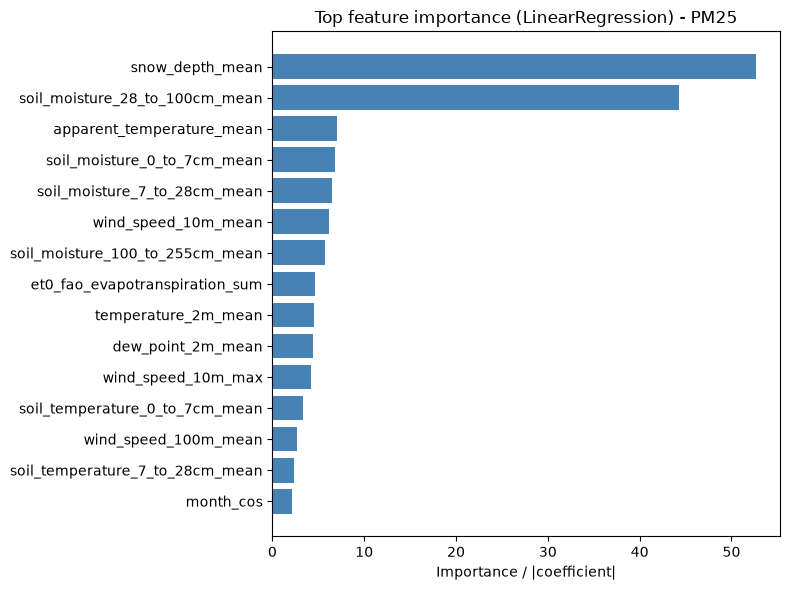


PM10 (RandomForest)


,feature,importance
0,pm10_lag_1,0.540270
46,soil_temperature_0_to_7cm_mean,0.130983
39,wind_gusts_10m_max,0.039797
4,pm10_rolling_7,0.026751
6,pm10_rolling_std_7,0.026254
41,wind_direction_100m_mean,0.022003
27,cloud_cover_low_mean,0.021720
38,wind_speed_100m_max,0.012607
28,cloud_cover_mid_mean,0.011866
2,pm10_lag_3,0.009873


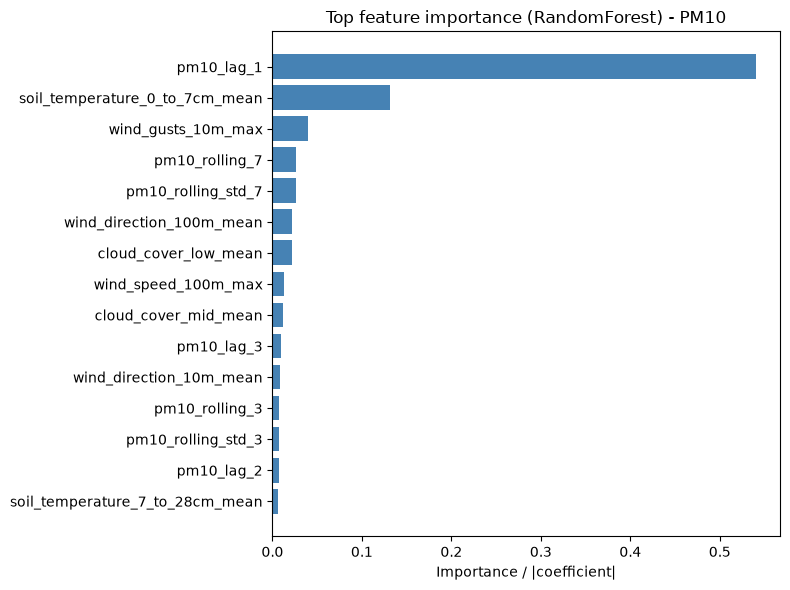

In [14]:
for pollutant in POLLUTANTS:
    entry = data[pollutant]
    best_model = results_by_pollutant[pollutant]["RMSE"].idxmin()
    best_fit_model = entry["models"][best_model]

    if hasattr(best_fit_model, "feature_importances_"):
        importance = best_fit_model.feature_importances_
    else:
        importance = np.abs(best_fit_model.coef_)

    imp_df = pd.DataFrame({"feature": entry["X"].columns, "importance": importance}).sort_values("importance", ascending=False)
    entry["importance"] = importance

    print(f"\n{pollutant.upper()} ({best_model})")
    display(imp_df.head(15))

    plt.figure(figsize=(8, 6))
    plot_df = imp_df.head(15).iloc[::-1]
    plt.barh(plot_df["feature"], plot_df["importance"], color="steelblue")
    plt.xlabel("Importance / |coefficient|")
    plt.title(f"Top feature importance ({best_model}) - {pollutant.upper()}")
    plt.tight_layout()
    plt.show()


In [15]:
def get_factor_groups(pollutant, feature_names):
    return {
        "Previous pollution (lag)": [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS],
        "Previous pollution (rolling)": [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS],
        "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
        "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
        "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
        "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
        "Pressure": [c for c in feature_names if "pressure" in c],
        "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
        "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
        "Soil": [c for c in feature_names if c.startswith("soil")],
        "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
        "Weather code": [c for c in feature_names if "weather_code" in c],
    }


In [16]:
def group_importance(importance, feature_names, factor_groups):
    factor_importance = []

    for factor, cols in factor_groups.items():
        present = [c for c in cols if c in feature_names]
        if not present:
            continue

        vals = [importance[feature_names.index(c)] for c in present]
        factor_importance.append({
            "factor": factor,
            "n_features": len(present),
            "importance_max": float(np.max(vals)),
            "importance_mean": float(np.mean(vals)),
        })

    return pd.DataFrame(factor_importance).sort_values("importance_mean", ascending=False)


In [17]:
factor_tables = {}

for pollutant in POLLUTANTS:
    entry = data[pollutant]
    feature_names = list(entry["X"].columns)
    factor_df = group_importance(entry["importance"], feature_names, get_factor_groups(pollutant, feature_names))
    factor_tables[pollutant] = factor_df

    print(f"\n{pollutant.upper()}")
    display(factor_df.round(4))



PM25


,factor,n_features,importance_max,importance_mean
5,Precipitation,5,52.6522,11.0398
9,Soil,8,44.2730,8.6524
2,Temperature,9,7.0167,2.5221
4,Wind,20,6.1148,1.8293
8,Season / calendar,5,2.1557,1.1533
10,Wind category,3,1.2151,0.8101
7,Clouds & radiation,9,4.6262,0.6384
3,Humidity,4,1.7122,0.6379
6,Pressure,5,1.7122,0.5164
0,Previous pollution (lag),3,0.4928,0.2269



PM10


,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.5403,0.1858
9,Soil,8,0.1310,0.0199
2,Temperature,9,0.1310,0.0179
1,Previous pollution (rolling),4,0.0268,0.0170
4,Wind,20,0.0398,0.0097
7,Clouds & radiation,9,0.0217,0.0060
3,Humidity,4,0.0053,0.0047
6,Pressure,5,0.0053,0.0032
5,Precipitation,5,0.0039,0.0015
8,Season / calendar,5,0.0032,0.0014


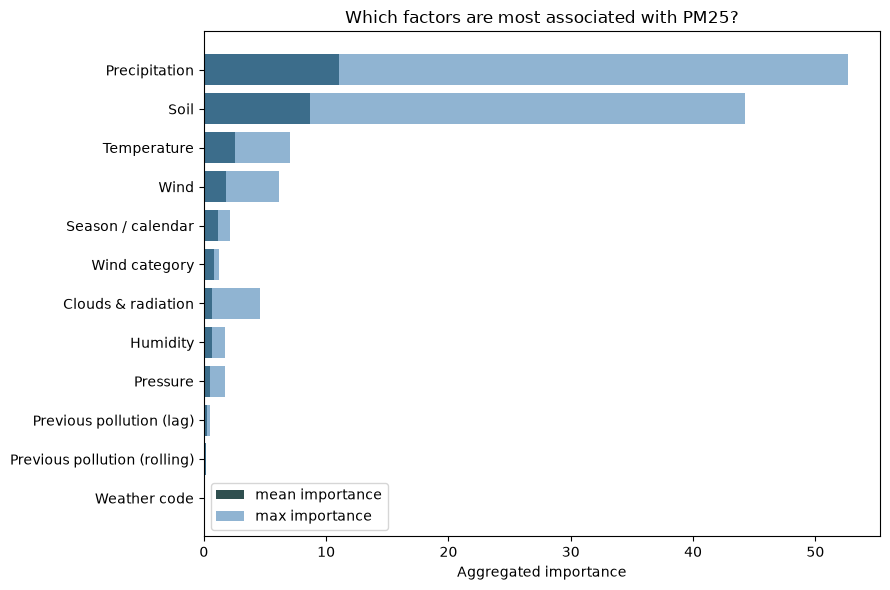

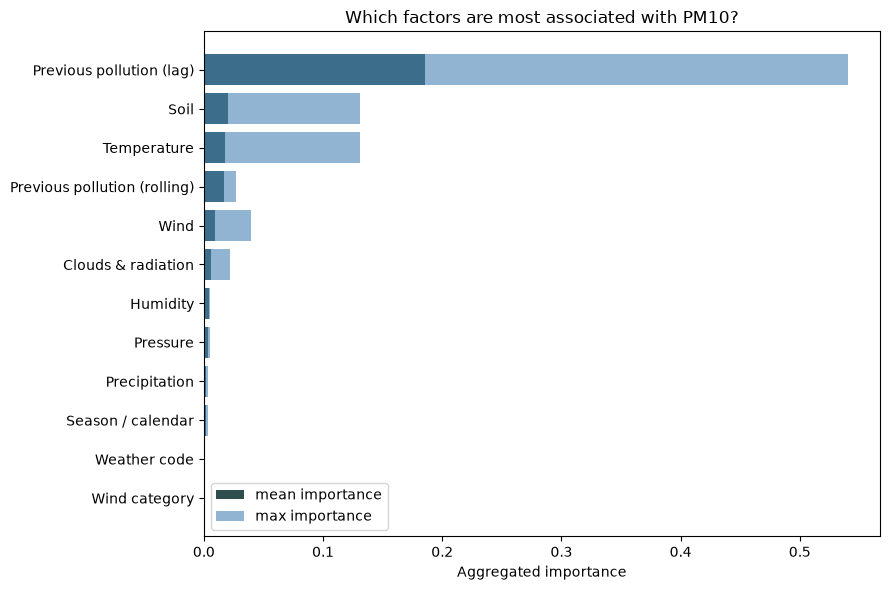

In [18]:
for pollutant in POLLUTANTS:
    factor_df = factor_tables[pollutant]

    plt.figure(figsize=(9, 6))
    plot_df = factor_df.iloc[::-1]
    plt.barh(plot_df["factor"], plot_df["importance_mean"], color="darkslategray", label="mean importance")
    plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
    plt.xlabel("Aggregated importance")
    plt.title(f"Which factors are most associated with {pollutant.upper()}?")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [19]:
for pollutant in POLLUTANTS:
    METRICS_OUT = PROCESSED_DIR / f"regression_metrics_{pollutant}.parquet"
    PRED_OUT = PROCESSED_DIR / f"regression_predictions_{pollutant}.parquet"

    results_by_pollutant[pollutant].to_parquet(METRICS_OUT)
    comparisons[pollutant].to_parquet(PRED_OUT, index=False)

    print(f"Saved: {METRICS_OUT.name}")
    print(f"Saved: {PRED_OUT.name}")


Saved: regression_metrics_pm25.parquet
Saved: regression_predictions_pm25.parquet
Saved: regression_metrics_pm10.parquet
Saved: regression_predictions_pm10.parquet
